In [ ]:
# foodrag bootstrap: run from repo root + load .env
from foodrag.notebook import setup
setup()

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
#import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
df=pd.read_csv("/kaggle/input/food-com-recipes-and-user-interactions/RAW_recipes.csv")
df

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/food-com-recipes-and-user-interactions/RAW_recipes.csv'

: 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   name            231636 non-null  object
 1   id              231637 non-null  int64 
 2   minutes         231637 non-null  int64 
 3   contributor_id  231637 non-null  int64 
 4   submitted       231637 non-null  object
 5   tags            231637 non-null  object
 6   nutrition       231637 non-null  object
 7   n_steps         231637 non-null  int64 
 8   steps           231637 non-null  object
 9   description     226658 non-null  object
 10  ingredients     231637 non-null  object
 11  n_ingredients   231637 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 21.2+ MB


In [5]:
df.describe()

,id,minutes,contributor_id,n_steps,n_ingredients
count,231637.000000,2.316370e+05,2.316370e+05,231637.000000,231637.000000
mean,222014.708984,9.398546e+03,5.534885e+06,9.765499,9.051153
std,141206.635626,4.461963e+06,9.979141e+07,5.995128,3.734796
min,38.000000,0.000000e+00,2.700000e+01,0.000000,1.000000
25%,99944.000000,2.000000e+01,5.690500e+04,6.000000,6.000000
50%,207249.000000,4.000000e+01,1.736140e+05,9.000000,9.000000
75%,333816.000000,6.500000e+01,3.982750e+05,12.000000,11.000000
max,537716.000000,2.147484e+09,2.002290e+09,145.000000,43.000000


In [6]:
df.shape

(231637, 12)

In [7]:
df.isna().sum()

name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

In [8]:
df['description'] = df['description'].fillna('No description')
df['name'] = df['name'].fillna('Unknown')

In [9]:
df.isna().sum()

name              0
id                0
minutes           0
contributor_id    0
submitted         0
tags              0
nutrition         0
n_steps           0
steps             0
description       0
ingredients       0
n_ingredients     0
dtype: int64

In [10]:
df.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [11]:
df.drop(["id", "contributor_id","submitted","tags","nutrition"], axis=1,inplace = True)

In [12]:
df

,name,minutes,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,55,11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,30,9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,130,6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,45,11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,190,5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8
...,...,...,...,...,...,...,...
231632,zydeco soup,60,7,"['heat oil in a 4-quart dutch oven', 'add cele...",this is a delicious soup that i originally fou...,"['celery', 'onion', 'green sweet pepper', 'gar...",22
231633,zydeco spice mix,5,1,['mix all ingredients together thoroughly'],this spice mix will make your taste buds dance!,"['paprika', 'salt', 'garlic powder', 'onion po...",13
231634,zydeco ya ya deviled eggs,40,7,"['in a bowl , combine the mashed yolks and may...","deviled eggs, cajun-style","['hard-cooked eggs', 'mayonnaise', 'dijon must...",8
231635,cookies by design cookies on a stick,29,9,['place melted butter in a large mixing bowl a...,"i've heard of the 'cookies by design' company,...","['butter', 'eagle brand condensed milk', 'ligh...",10


In [13]:
df['n_steps'].value_counts()

n_steps
7      20785
8      19980
6      19927
9      18265
5      18047
       ...  
93         1
77         1
108        1
80         1
98         1
Name: count, Length: 94, dtype: int64

In [14]:
df['n_ingredients'].value_counts()

n_ingredients
8     25532
7     24599
9     24599
10    22430
6     21840
11    19094
5     18217
12    15165
4     12650
13    11640
14     8284
3      6800
15     6014
16     4145
17     2793
2      2127
18     1913
19     1279
20      852
21      529
22      346
23      244
24      178
25      107
26       68
27       55
28       33
1        25
29       22
30       20
31       13
32        5
33        4
35        4
34        3
37        2
40        2
43        1
38        1
36        1
39        1
Name: count, dtype: int64

In [15]:
df["minutes"].agg({"min","max","mean"})

max     2.147484e+09
min     0.000000e+00
mean    9.398546e+03
Name: minutes, dtype: float64

In [16]:
df.groupby("n_ingredients")["minutes"].mean()

n_ingredients
1        86.600000
2      1079.518571
3       360.868676
4       198.930988
5       125.099138
6       103.121749
7       104.253506
8     84219.968040
9       101.738851
10       89.257200
11       93.820886
12       99.338543
13      106.796649
14       99.070135
15      114.165115
16      121.946924
17      150.269961
18      135.840042
19      138.866302
20      149.968310
21      144.640832
22      296.774566
23      157.561475
24      142.640449
25      328.233645
26      143.367647
27      538.636364
28      249.303030
29      122.090909
30      137.900000
31      178.076923
32      202.000000
33       80.000000
34      173.333333
35      588.750000
36      165.000000
37      172.500000
38       55.000000
39      270.000000
40      200.000000
43       80.000000
Name: minutes, dtype: float64

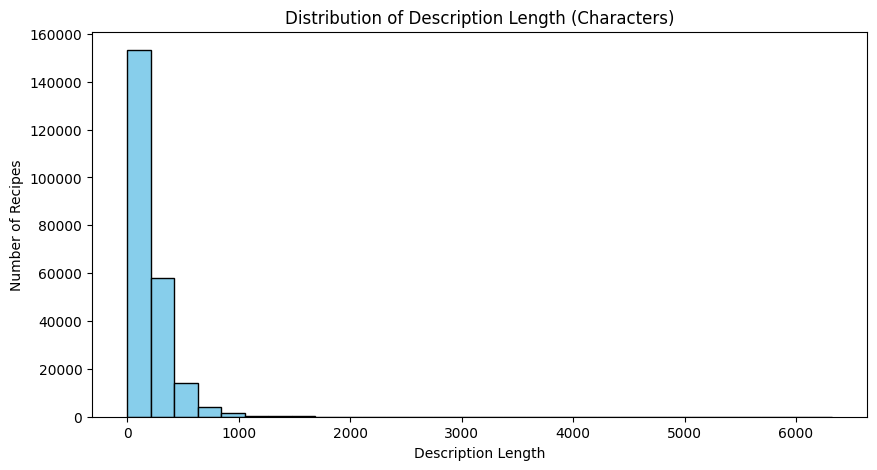

In [17]:
plt.figure(figsize=(10,5))
plt.hist(df['description'].fillna('No description').str.len(), bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Description Length (Characters)')
plt.xlabel('Description Length')
plt.ylabel('Number of Recipes')
plt.show()

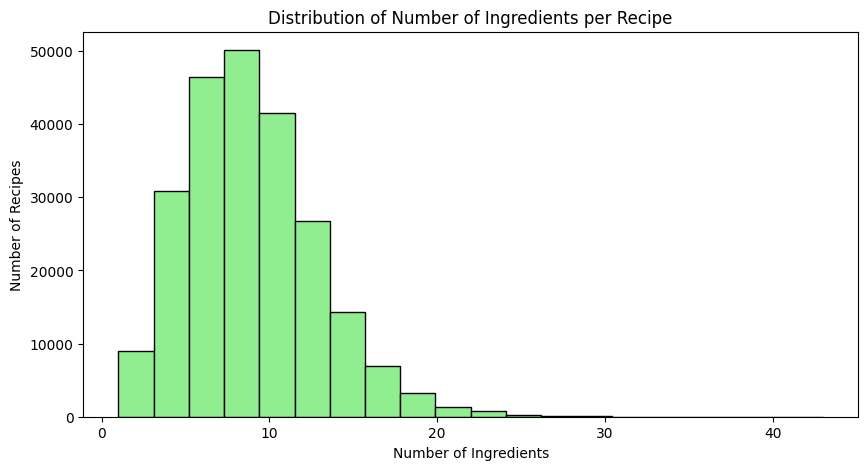

In [18]:
plt.figure(figsize=(10,5))
plt.hist(df['n_ingredients'].fillna(0), bins=20, color='lightgreen', edgecolor='black')
plt.title('Distribution of Number of Ingredients per Recipe')
plt.xlabel('Number of Ingredients')
plt.ylabel('Number of Recipes')
plt.show()

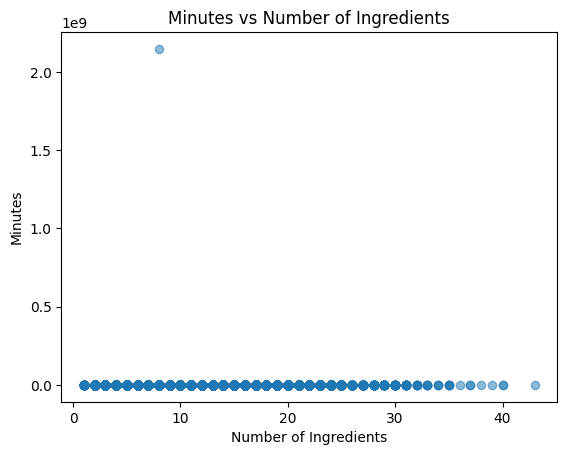

In [19]:
plt.scatter(df['n_ingredients'], df['minutes'], alpha=0.5)
plt.title('Minutes vs Number of Ingredients')
plt.xlabel('Number of Ingredients')
plt.ylabel('Minutes')
plt.show()